DATA PREPROCESSING

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df=pd.read_csv('shopease_raw_orders.csv')

In [4]:
df.head()

,OrderID,CustomerID,OrderDate,CustomerAge,Gender,City,Category,Product,Quantity,UnitPrice,Discount,PaymentMethod,OrderStatus,DeliveryDate,Rating,TotalAmount
0,18129,C0507,2026-02-01 23:39:00,68.0,Female,Alexandria,Electronics,Laptop,4,18000,0.0,Wallet,Delivered,2026-02-04 23:39:00,5.0,72000.0
1,11666,C0207,2026-03-03 10:37:00,21.0,Female,Cairo,Sports,Yoga Mat,2,600,0.1,Wallet,Delivered,2026-03-07 10:37:00,1.0,1080.0
2,12859,C1112,2026-05-23 17:57:00,23.0,Male,Aswan,Fashion,Shoes,-1,1500,10%,Bank Transfer,Delivered,2026-05-27 17:57:00,4.0,1350.0
3,19787,C1322,2026-01-29 07:51:00,23.0,Male,Tanta,Beauty,Hair Dryer,4,1300,0.1,Wallet,Delivered,2026-01-30 07:51:00,4.0,4680.0
4,16473,C0314,2026-06-23 20:17:00,62.0,Female,Tanta,Electronics,Laptop,1,18000,0.1,Mastercard,Delivered,2026-06-27 20:17:00,5.0,16200.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10020 entries, 0 to 10019
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        10020 non-null  int64  
 1   CustomerID     10005 non-null  object 
 2   OrderDate      10020 non-null  object 
 3   CustomerAge    9900 non-null   float64
 4   Gender         10020 non-null  object 
 5   City           10020 non-null  object 
 6   Category       10020 non-null  object 
 7   Product        10000 non-null  object 
 8   Quantity       10020 non-null  int64  
 9   UnitPrice      10020 non-null  int64  
 10  Discount       9920 non-null   object 
 11  PaymentMethod  9970 non-null   object 
 12  OrderStatus    10020 non-null  object 
 13  DeliveryDate   7790 non-null   object 
 14  Rating         7728 non-null   float64
 15  TotalAmount    10020 non-null  float64
dtypes: float64(3), int64(3), object(10)
memory usage: 1.2+ MB


In [7]:
df.describe()

,OrderID,CustomerAge,Quantity,UnitPrice,Rating,TotalAmount
count,10020.000000,9900.000000,10020.000000,10020.000000,7728.000000,10020.000000
mean,14999.295908,44.381212,1.947605,1956.412176,3.958851,3308.779741
std,2888.444735,15.703142,1.100476,5403.755496,1.023657,7328.702149
min,10001.000000,-3.000000,-3.000000,-500.000000,-1.000000,200.000000
25%,12496.750000,31.000000,1.000000,650.000000,3.000000,855.000000
50%,14998.500000,44.000000,2.000000,900.000000,4.000000,1600.000000
75%,17501.250000,58.000000,3.000000,1500.000000,5.000000,2853.250000
max,20000.000000,150.000000,4.000000,150000.000000,6.000000,72000.000000


In [9]:
df.columns

Index(['OrderID', 'CustomerID', 'OrderDate', 'CustomerAge', 'Gender', 'City',
       'Category', 'Product', 'Quantity', 'UnitPrice', 'Discount',
       'PaymentMethod', 'OrderStatus', 'DeliveryDate', 'Rating',
       'TotalAmount'],
      dtype='object')

In [10]:
# there are 7 integer type columns and one semi-int type column and the rest are object type columns

In [12]:
df.isnull().sum()

OrderID             0
CustomerID         15
OrderDate           0
CustomerAge       120
Gender              0
City                0
Category            0
Product            20
Quantity            0
UnitPrice           0
Discount          100
PaymentMethod      50
OrderStatus         0
DeliveryDate     2230
Rating           2292
TotalAmount         0
dtype: int64

In [14]:
# So there are many null values too. We have to remove the null values to make the data more refined
# and usefull.

In [15]:
df.nunique()

OrderID          10000
CustomerID        1988
OrderDate         9687
CustomerAge         56
Gender              10
City                30
Category            20
Product             90
Quantity             8
UnitPrice           25
Discount            10
PaymentMethod       20
OrderStatus         13
DeliveryDate      7653
Rating               8
TotalAmount        329
dtype: int64

In [16]:
cat_col=df.select_dtypes(include=['object']).columns
num_col=df.select_dtypes(include=np.number).columns.tolist()
print(cat_col)
print(num_col)

Index(['CustomerID', 'OrderDate', 'Gender', 'City', 'Category', 'Product',
       'Discount', 'PaymentMethod', 'OrderStatus', 'DeliveryDate'],
      dtype='object')
['OrderID', 'CustomerAge', 'Quantity', 'UnitPrice', 'Rating', 'TotalAmount']


In [17]:
# These above are the catagorical and numerical columns.

Data Cleaning/Refining

Standardizing text fields

In [45]:
df['Category'] = df['Category'].str.strip().str.title()
df['City'] = df['City'].str.strip().str.title()
df['PaymentMethod'] = df['PaymentMethod'].str.strip()
df['OrderStatus'] = df['OrderStatus'].str.strip()

In [46]:
# Fixing date

In [47]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'], format='mixed', errors='coerce')

Fixing discount

In [48]:
df['Discount'] = pd.to_numeric(df['Discount'].astype(str).str.rstrip('%'), errors='coerce').fillna(0)

Removing unwanted data

In [49]:
df = df[df['Quantity'] > 0]

Creating time columns

In [51]:
df['YearMonth'] = df['OrderDate'].dt.to_period('M')
df['Month'] = df['OrderDate'].dt.month
df['Year'] = df['OrderDate'].dt.year

C:\Users\Chitwan bajpai\AppData\Local\Temp\ipykernel_5096\1846855857.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['YearMonth'] = df['OrderDate'].dt.to_period('M')
C:\Users\Chitwan bajpai\AppData\Local\Temp\ipykernel_5096\1846855857.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Month'] = df['OrderDate'].dt.month
C:\Users\Chitwan bajpai\AppData\Local\Temp\ipykernel_5096\1846855857.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

So we have some insights by looking at the data. We have to look for reasonable analysis which should be useful for the market and buisness.
There are several points -
1. Sales trends by Category over time
2. Rating distribution by Category (customer satisfaction benchmark)
3. Geographic analysis (orders/revenue by City)
4. Payment method preferences by Category
5. Revenue vs Quantity/Discount relationships

1. Sales trends

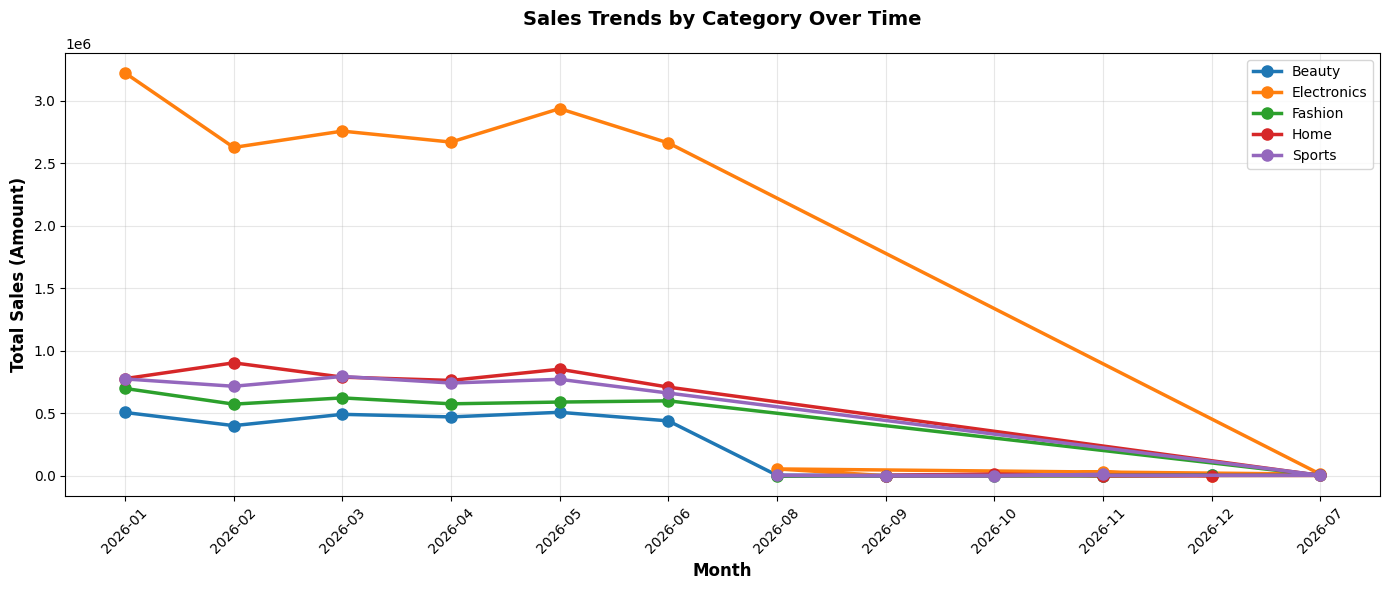

In [55]:
sales_trend = df.groupby(['YearMonth', 'Category'])['TotalAmount'].sum().reset_index()

#Converting Period to string BEFORE plotting
sales_trend['YearMonth'] = sales_trend['YearMonth'].astype(str)

#Create figure ONCE
plt.figure(figsize=(14, 6))


for category in sales_trend['Category'].unique():
    category_data = sales_trend[sales_trend['Category'] == category]
    plt.plot(category_data['YearMonth'], category_data['TotalAmount'], 
             marker='o', linewidth=2.5, markersize=8, label=category)


plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Total Sales (Amount)', fontsize=12, fontweight='bold')
plt.title('Sales Trends by Category Over Time', fontsize=14, fontweight='bold', pad=20)
plt.legend(loc='best', fontsize=10)
plt.xticks(rotation=45) 
plt.grid(True, alpha=0.3)
plt.tight_layout()


plt.savefig('plot_1_sales_trend.png', dpi=300, bbox_inches='tight')
plt.show()

It shows how each product category's sales evolved month bymonth
Insights:
1. Electronics dominates revenue
2. All categories show declining trend from Feb-June
3. Useful for identifying seasonal patterns

2.  RATING DISTRIBUTION BY CATEGORY

In [56]:
 df_ratings = df[df['Rating'].notna()].copy()

c:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


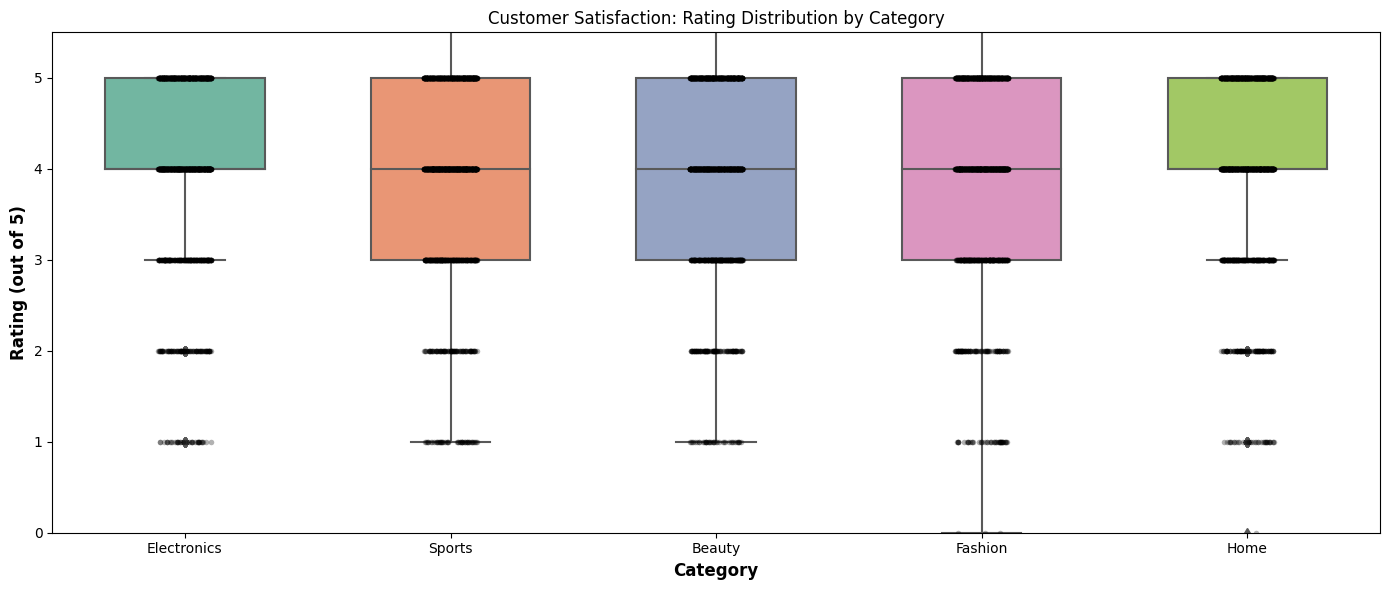

In [57]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_ratings, x='Category', y='Rating', palette='Set2', width=0.6)
sns.stripplot(data=df_ratings, x='Category', y='Rating', color='black', alpha=0.3, size=4)

plt.xlabel('Category', fontsize=12, fontweight='bold')
plt.ylabel('Rating (out of 5)', fontsize=12, fontweight='bold')
plt.title('Customer Satisfaction: Rating Distribution by Category')
plt.ylim(0, 5.5)
plt.tight_layout()
plt.show()

it Shows customer satisfaction levels (ratings) across product categories

KEY INSIGHTS:
  1. Home category has highest average satisfaction (3.88/5)
  2. Sports also shows strong customer satisfaction (3.83/5)
  3. Wide rating distribution may indicate quality inconsistency

3. GEOGRAPHIC ANALYSIS

In [58]:
df['City'] = df['City'].str.strip().str.title()

C:\Users\Chitwan bajpai\AppData\Local\Temp\ipykernel_5096\1035329960.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['City'] = df['City'].str.strip().str.title()


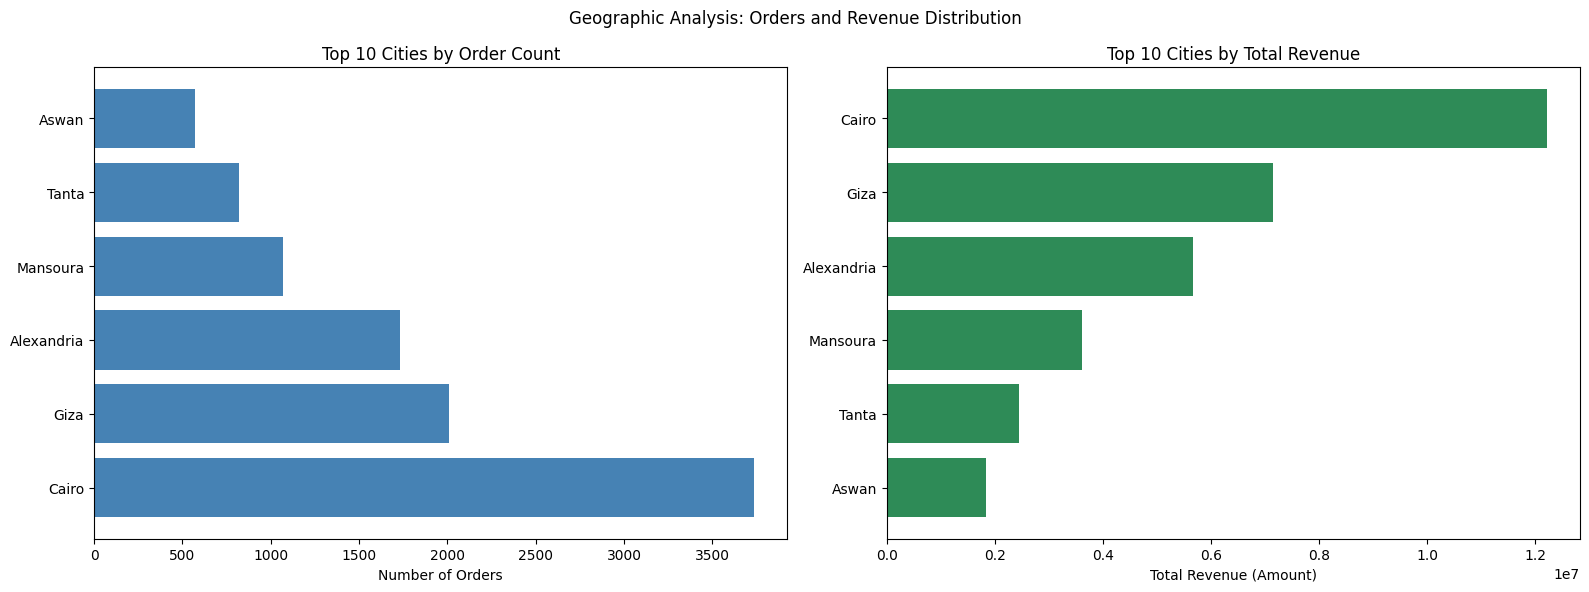

In [59]:
city_orders = df['City'].value_counts().head(10)
city_revenue = df.groupby('City')['TotalAmount'].sum().sort_values(ascending=True).tail(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


axes[0].barh(city_orders.index, city_orders.values, color='steelblue')
axes[0].set_xlabel('Number of Orders')
axes[0].set_title('Top 10 Cities by Order Count')


axes[1].barh(city_revenue.index, city_revenue.values, color='seagreen')
axes[1].set_xlabel('Total Revenue (Amount)')
axes[1].set_title('Top 10 Cities by Total Revenue')

plt.suptitle('Geographic Analysis: Orders and Revenue Distribution')
plt.tight_layout()
plt.show()

 Shows where customers are located and which cities generate most revenue

1. Cairo: ~40% of orders, ~47% of revenue (dominant market)
2. Giza: Secondary market with strong presence
3. Growth opportunity in smaller cities

4. PAYMENT METHOD PREFERENCES BY CATEGORY

heatmap

In [60]:
df['PaymentMethod'] = df['PaymentMethod'].str.strip()

C:\Users\Chitwan bajpai\AppData\Local\Temp\ipykernel_5096\1884449102.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['PaymentMethod'] = df['PaymentMethod'].str.strip()


In [61]:
payment_category = pd.crosstab(df['Category'], df['PaymentMethod'])

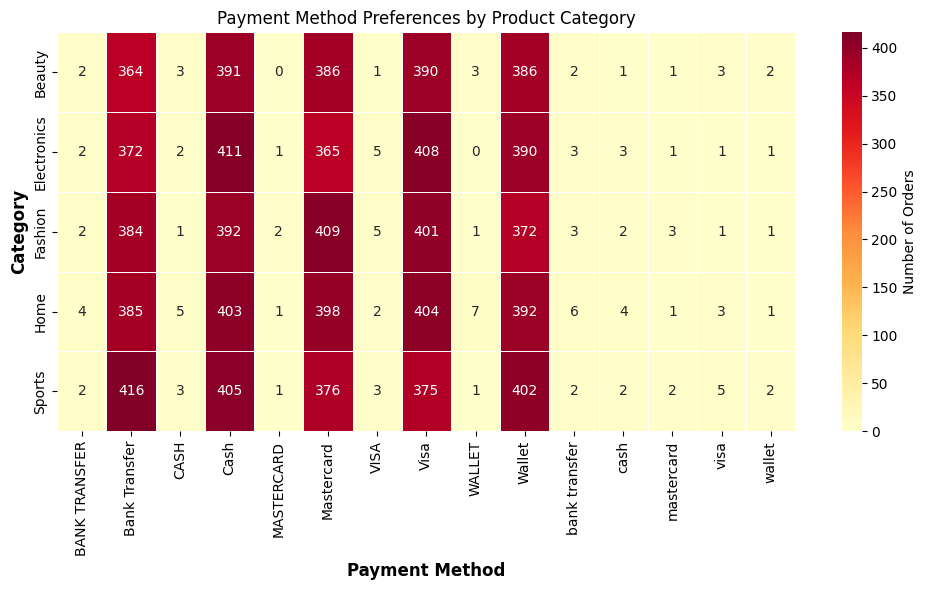

In [62]:
plt.figure(figsize=(10, 6))
sns.heatmap(payment_category, annot=True, fmt='d', cmap='YlOrRd',cbar_kws={'label': 'Number of Orders'}, linewidths=0.5)

plt.xlabel('Payment Method', fontsize=12, fontweight='bold')
plt.ylabel('Category', fontsize=12, fontweight='bold')
plt.title('Payment Method Preferences by Product Category')
plt.tight_layout()
plt.show()

Grouped bar graph

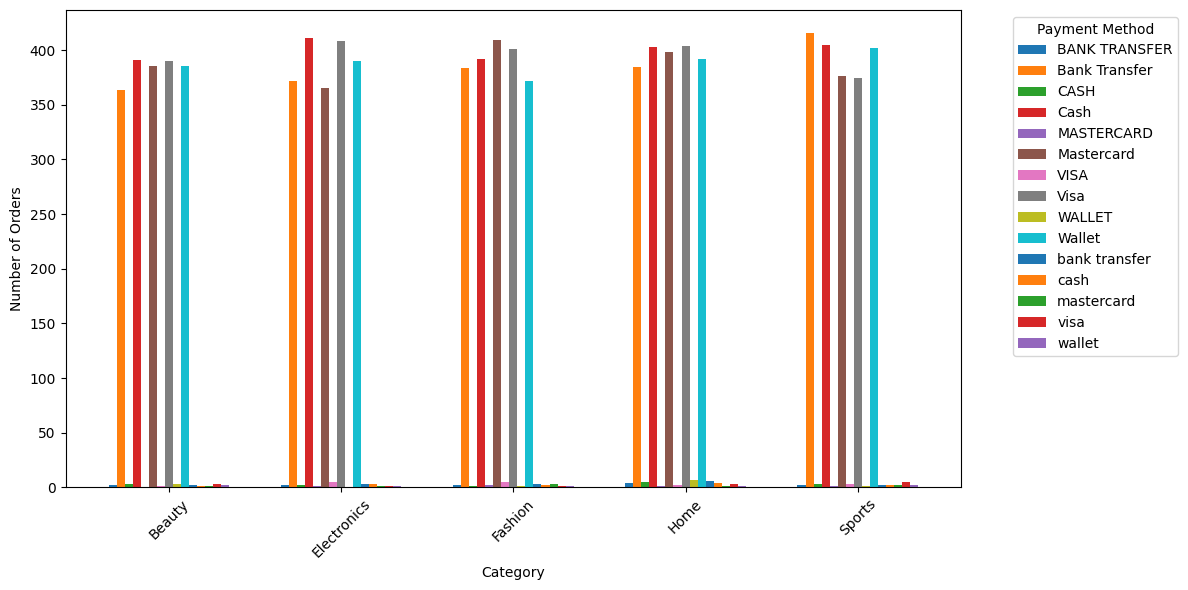

In [63]:
fig, ax = plt.subplots(figsize=(12, 6))
payment_category.plot(kind='bar', stacked=False, ax=ax, width=0.7)
plt.xlabel('Category')
plt.ylabel('Number of Orders')
plt.legend(title='Payment Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Shows which payment methods customers prefer for different product categories

1. Wallet is dominant across most categories
2. Visa/Mastercard are also popular (~350-400 orders each)
3. Some payment methods underutilized

5. REVENUE VS QUANTITY/DISCOUNT RELATIONSHIPS

In [64]:
categories = df['Category'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(categories)))

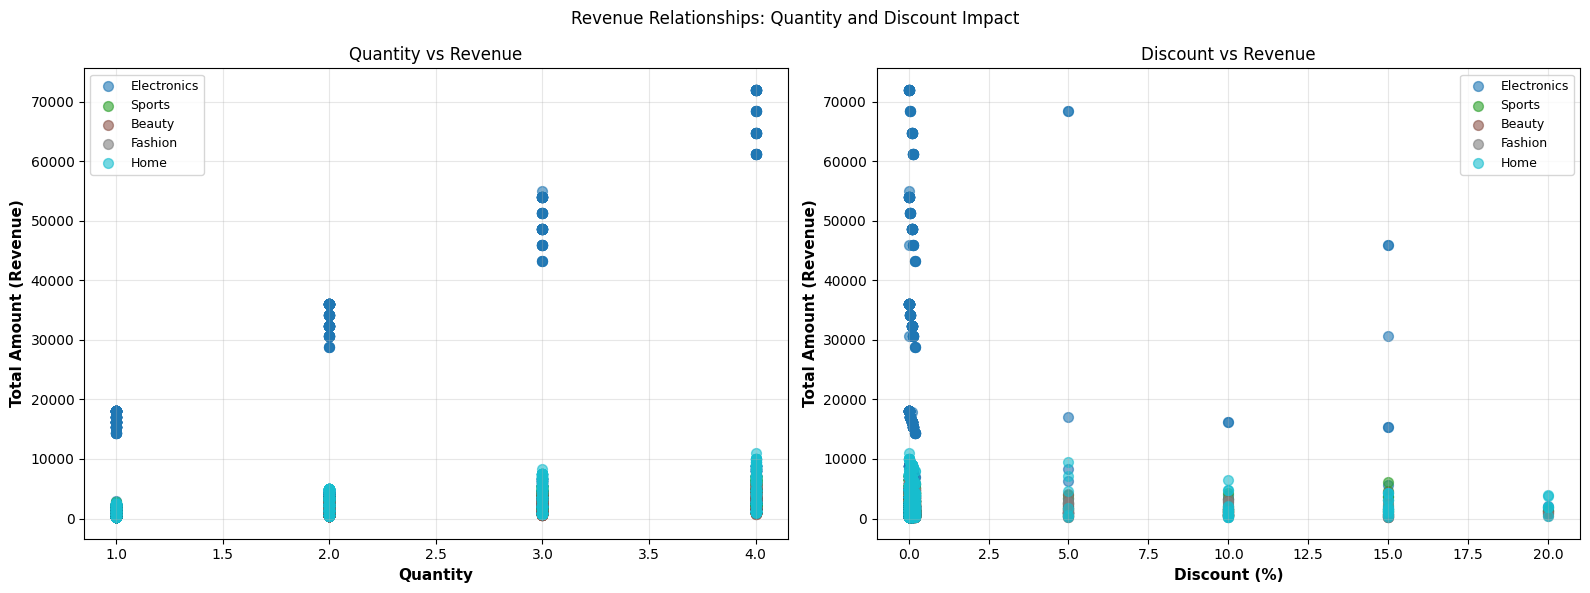

In [65]:
# Left 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for idx, category in enumerate(categories):
    category_data = df[df['Category'] == category]
    axes[0].scatter(category_data['Quantity'], category_data['TotalAmount'],color=colors[idx], label=category, alpha=0.6, s=50)

axes[0].set_xlabel('Quantity', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Total Amount (Revenue)', fontsize=11, fontweight='bold')
axes[0].set_title('Quantity vs Revenue')
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(True, alpha=0.3)
 

# Right
for idx, category in enumerate(categories):
    category_data = df[df['Category'] == category]
    axes[1].scatter(category_data['Discount'], category_data['TotalAmount'],color=colors[idx], label=category, alpha=0.6, s=50)

axes[1].set_xlabel('Discount (%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Total Amount (Revenue)', fontsize=11, fontweight='bold')
axes[1].set_title('Discount vs Revenue')
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(True, alpha=0.3)


plt.suptitle('Revenue Relationships: Quantity and Discount Impact')
plt.tight_layout()
plt.show()

Shows how quantity purchased and discounts offered affect total revenue

 1. Weak correlation between Quantity and Revenue (unit price matters more)
  2. Discounts show variable impact on revenue
  3. Electronics and Home categories command highest prices